# Bulgarian powerlifting results: what three meets show

Data: standard-layout results files of the БФСТ national championship rounds, read with `bgopl.analysis.load_frames`.
Everything below is **aggregate**: no names are loaded, so the tables and charts contain no personal data.
Lifters are followed across meets by a short hash of sex and name (`lifter_id`), which is pseudonymous, not anonymous.

Questions:
1. Who competes? (meets, sex, division, weight classes)
2. How strong is the field, and how do the sexes and divisions compare on IPF GL points?
3. Where are lifts missed? (success rate by lift and attempt number)
4. How do lifters choose attempts, and how much do the lifts contribute to the total?
5. Do lifters who compete again improve?
6. How clean is the source data?

Set `BGOPL_DATA_DIR` to a folder with the normalised files (default `../data`).

In [3]:
import os

import matplotlib.pyplot as plt
import numpy as np

from bgopl.analysis import load_frames

DATA = os.environ.get("BGOPL_DATA_DIR", "../data")
lifters, attempts, findings = load_frames(DATA)

COLOR = {"F": "#d9730d", "M": "#1f6feb"}
LIFT_COLOR = {"squat": "#4c78a8", "bench": "#e45756", "deadlift": "#72b7b2"}
LABEL = {"F": "Women", "M": "Men"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True})

classic = lifters[(lifters.equipment == "classic")]
ranked = classic[classic.status == "ranked"]
print(f"{len(lifters)} lifter rows, {len(attempts)} attempts, {lifters.meet.nunique()} meets")

451 lifter rows, 3983 attempts, 4 meets


## 1. Who competes

In [4]:
overview = (lifters.assign(women=lifters.sex.eq("F"), men=lifters.sex.eq("M"))
            .groupby("meet", observed=True)
            .agg(lifters=("status", "size"),
                 ranked=("status", lambda s: (s == "ranked").sum()),
                 guests=("status", lambda s: (s == "guest").sum()),
                 disqualified=("status", lambda s: (s == "disqualified").sum()),
                 women=("women", "sum"), men=("men", "sum"),
                 equipped=("equipment", lambda s: (s == "equipped").sum())))
overview["women_share_%"] = (100 * overview.women / overview.lifters).round(1)
overview["dq_rate_%"] = (100 * overview.disqualified / overview.lifters).round(1)
overview

,lifters,ranked,guests,disqualified,women,men,equipped,women_share_%,dq_rate_%
meet,,,,,,,,,
2024-11-16,171,167,1,3,34,137,0,19.9,1.8
2026-04-03,128,120,0,8,23,105,0,18.0,6.2
2026-09-19,84,82,1,1,15,69,4,17.9,1.2
2026-11-01,68,68,0,0,9,59,0,13.2,0.0


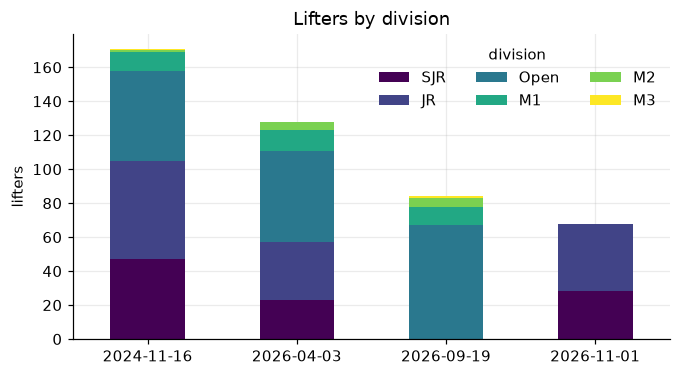

division,SJR,JR,Open,M1,M2,M3
meet,,,,,,
2024-11-16,47,58,53,11,1,1
2026-04-03,23,34,54,12,5,0
2026-09-19,0,0,67,11,5,1
2026-11-01,28,40,0,0,0,0


In [5]:
mix = (lifters.groupby(["meet", "division"], observed=True).size().unstack(fill_value=0)
       [["SJR", "JR", "Open", "M1", "M2", "M3"]])
ax = mix.plot.bar(stacked=True, figsize=(7, 3.6), rot=0, colormap="viridis")
ax.set_ylabel("lifters"); ax.set_xlabel(""); ax.set_title("Lifters by division")
ax.legend(title="division", ncol=3, frameon=False)
plt.show()
mix

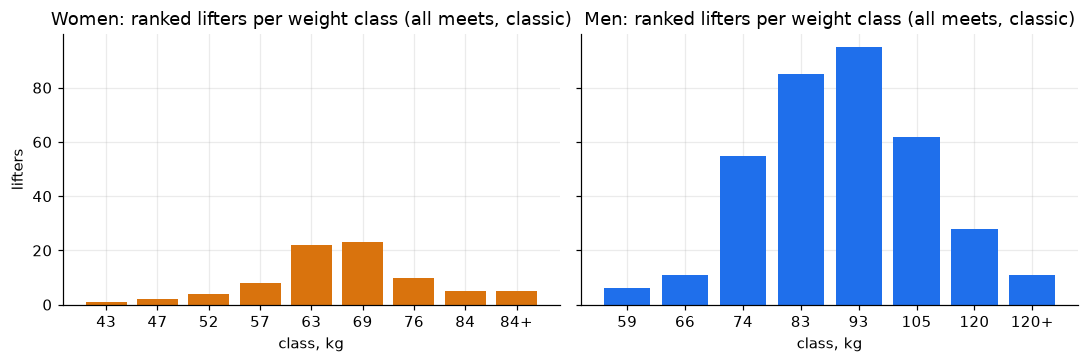

In [6]:
def class_order(label):
    return (label.endswith("+"), float(label.rstrip("+")))

size = (ranked.groupby(["sex", "class_label"]).size().rename("lifters").reset_index())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, sex in zip(axes, "FM"):
    d = size[size.sex == sex].sort_values("class_label", key=lambda s: s.map(class_order))
    ax.bar(d.class_label, d.lifters, color=COLOR[sex])
    ax.set_title(f"{LABEL[sex]}: ranked lifters per weight class (all meets, classic)")
    ax.set_xlabel("class, kg")
axes[0].set_ylabel("lifters")
plt.tight_layout(); plt.show()

Women are about 18 to 20% of the field at each meet. Their classes are small (most have fewer than 10 ranked lifters over all three meets, and the peak is the 63 and 69 kg classes), while the men's field is concentrated in the 83 and 93 kg classes, each with more than 70 ranked lifters, with 74 and 105 kg next. A class ranking therefore compares few women, and a points ranking is needed to compare people across classes. The division mix is partly an artefact of how the files are organised: the September 2026 file lists everyone under Open and veterans, with no junior divisions, so the SJR and JR counts of that meet are zero.

## 2. Strength: bodyweight, total and IPF GL points

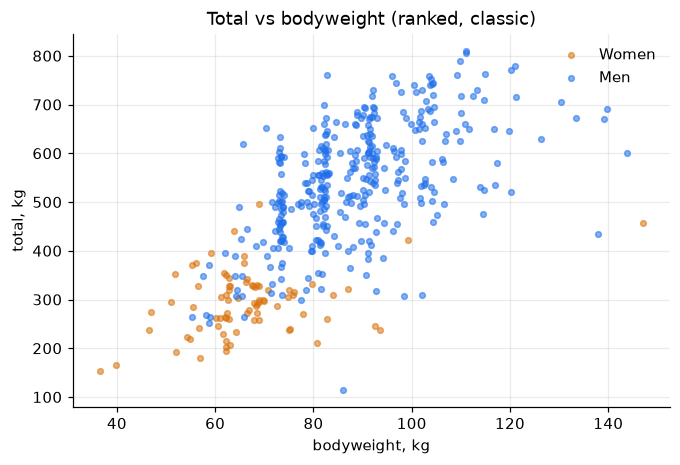

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.4))
for sex in "FM":
    d = ranked[ranked.sex == sex]
    ax.scatter(d.bodyweight, d.total, s=14, alpha=.55, color=COLOR[sex], label=LABEL[sex])
ax.set_xlabel("bodyweight, kg"); ax.set_ylabel("total, kg")
ax.set_title("Total vs bodyweight (ranked, classic)"); ax.legend(frameon=False)
plt.show()

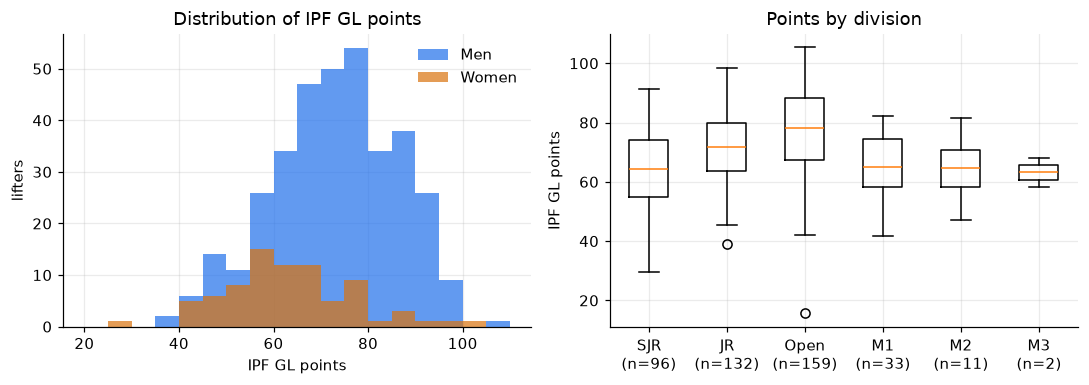

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
F,80.0,63.3,13.3,29.5,55.0,61.2,70.4,102.6
M,353.0,72.8,13.5,15.6,63.6,73.7,82.7,105.3


In [8]:
pts = ranked.dropna(subset=["points"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.arange(20, 115, 5)
for sex in "FM":
    pass
for sex in "MF":  # men first, so the smaller women's histogram is drawn on top
    axes[0].hist(pts[pts.sex == sex].points, bins=bins, alpha=.7, color=COLOR[sex], label=LABEL[sex])
axes[0].set_xlabel("IPF GL points"); axes[0].set_ylabel("lifters"); axes[0].legend(frameon=False)
axes[0].set_title("Distribution of IPF GL points")
order = ["SJR", "JR", "Open", "M1", "M2", "M3"]
data = [pts[pts.division == d].points for d in order]
axes[1].boxplot(data, tick_labels=[f"{d}\n(n={len(x)})" for d, x in zip(order, data)])
axes[1].set_ylabel("IPF GL points"); axes[1].set_title("Points by division")
plt.tight_layout(); plt.show()
pts.groupby("sex").points.describe().round(1)

In [ ]:
(pts.groupby(["division", "sex"]).points.agg(["count", "median", "max"]).round(1)
 .unstack("sex").dropna(how="all"))

count        median          max       
sex          F      M      F     M      F      M
division                                        
JR        13.0   79.0   59.9  72.6   72.5   98.3
M1         7.0   26.0   65.2  64.4   77.2   82.1
M2         1.0   10.0   47.1  65.9   47.1   81.5
M3         NaN    2.0    NaN  63.2    NaN   68.2
Open      34.0  125.0   65.1  79.5  102.6  105.3
SJR       16.0   52.0   58.6  65.7   89.2   90.1

## 3. Where lifts are missed

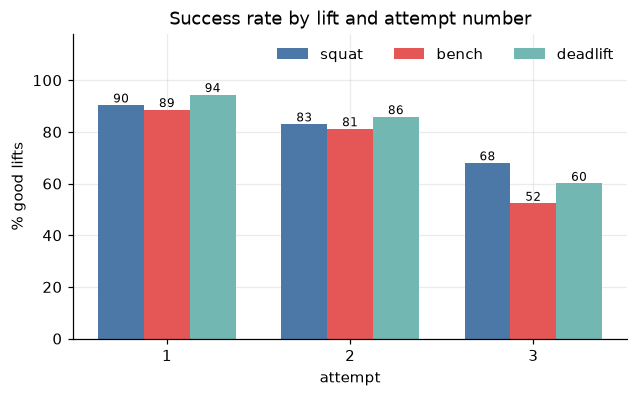

attempts taken,1,2,3
lift,,,
bench,447,441,430
deadlift,446,438,433
squat,446,442,428


In [9]:
taken = attempts[attempts.equipment == "classic"]
rate = (taken.groupby(["lift", "attempt"]).good.agg(["mean", "size"]).reset_index())
fig, ax = plt.subplots(figsize=(6.5, 3.6))
width = .25
for i, lift in enumerate(["squat", "bench", "deadlift"]):
    d = rate[rate.lift == lift]
    bars = ax.bar(d.attempt + (i - 1) * width, 100 * d["mean"], width, label=lift,
                  color=LIFT_COLOR[lift])
    for b, v in zip(bars, d["mean"]):
        ax.text(b.get_x() + b.get_width() / 2, 100 * v + 1, f"{100 * v:.0f}", ha="center", fontsize=8)
ax.set_xticks([1, 2, 3]); ax.set_xlabel("attempt"); ax.set_ylabel("% good lifts")
ax.set_ylim(0, 118); ax.set_title("Success rate by lift and attempt number")
ax.legend(frameon=False, ncol=3, loc="upper right")
plt.show()
rate.pivot(index="lift", columns="attempt", values="size").rename_axis(columns="attempts taken")

In [10]:
nine = (classic.merge(attempts[attempts.good].groupby(["meet", "lifter_id"]).size().rename("good9").reset_index(),
                      on=["meet", "lifter_id"], how="left"))
nine["good9"] = nine.good9.fillna(0)
full = attempts.groupby(["meet", "lifter_id"]).size().rename("taken").reset_index()
both = nine.merge(full, on=["meet", "lifter_id"])
both = both[both.taken == 9]
print(f"lifters who took all nine attempts: {len(both)}")
print(f"  nine good lifts: {(both.good9 == 9).mean():.1%}")
print(f"  at least seven good: {(both.good9 >= 7).mean():.1%}")
print(f"  at most five good: {(both.good9 <= 5).mean():.1%}")

lifters who took all nine attempts: 404
  nine good lifts: 16.3%
  at least seven good: 68.6%
  at most five good: 14.4%


Reading the chart: each bar counts only the attempts that were taken, so attempt 3 is conditional on the lifter getting that far and is not directly comparable with attempt 1. Success falls with every attempt, as expected when lifters choose heavier weights. The **bench press third attempt is the hardest** (50% good, against 59% in the deadlift and 66% in the squat); the deadlift opener is the safest attempt of the day (94%). Of the 340 lifters who took all nine attempts, 15% made all nine and about two thirds made seven or more.

## 4. How attempts are chosen, and where the total comes from

In [11]:
wide = (taken.pivot_table(index=["meet", "lifter_id", "lift"], columns="attempt", values="weight")
        .dropna(subset=[1, 2]).reset_index())
wide["jump2_%"] = 100 * (wide[2] / wide[1] - 1)
wide["jump3_%"] = 100 * (wide[3] / wide[2] - 1)
wide.groupby("lift")[["jump2_%", "jump3_%"]].median().round(1)

attempt,jump2_%,jump3_%
lift,,
bench,6.2,4.0
deadlift,6.6,4.6
squat,6.0,4.3


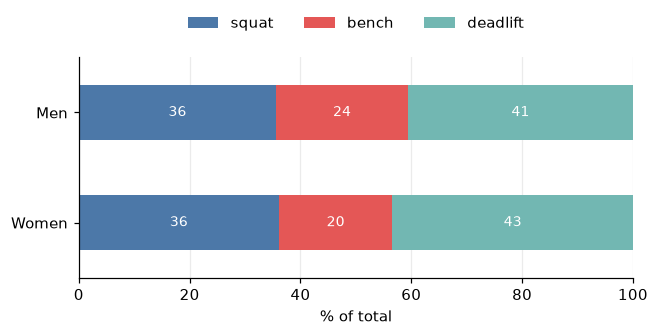

,squat,bench,deadlift
sex,,,
F,36.1,20.5,43.4
M,35.6,23.8,40.6


In [12]:
sh = ranked.dropna(subset=["best_squat", "best_bench", "best_deadlift", "total"]).copy()
for lift in ["squat", "bench", "deadlift"]:
    sh[lift] = 100 * sh[f"best_{lift}"] / sh.total
share = sh.groupby("sex")[["squat", "bench", "deadlift"]].mean().round(1)
ax = share.rename(index=LABEL).plot.barh(stacked=True, figsize=(6.5, 2.6), color=list(LIFT_COLOR.values()))
ax.set_xlabel("% of total"); ax.set_ylabel(""); ax.set_xlim(0, 100)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.25))
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", label_type="center", color="white", fontsize=9)
plt.show()
share

The median lifter adds about 6% to the weight on the second attempt and about 4% on the third, nearly the same in all three lifts. The deadlift is the biggest contributor to the total for both sexes (43% for women, 41% for men), the squat is equal (about 36%), and women get less of their total from the bench press (21% against 24%).

## 5. Do lifters who compete again improve?

96 lifters with at least two classic results (name-based identity)
median change in IPF GL: +4.3; improved: 80%


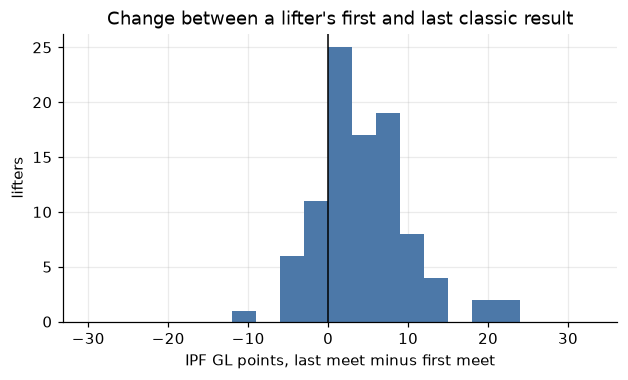

In [13]:
one_row = ranked.dropna(subset=["points"]).copy()
count = one_row.groupby(["lifter_id", "meet"], observed=True).size().rename("n").reset_index()
clean = count[count.n == 1][["lifter_id", "meet"]]  # drop names that occur twice in a meet (two people)
one_row = one_row.merge(clean, on=["lifter_id", "meet"])
first_last = (one_row.sort_values("meet").groupby("lifter_id")
              .agg(first=("points", "first"), last=("points", "last"), n=("meet", "nunique")))
rep = first_last[first_last.n >= 2].copy()
rep["change"] = rep["last"] - rep["first"]
print(f"{len(rep)} lifters with at least two classic results (name-based identity)")
print(f"median change in IPF GL: {rep.change.median():+.1f}; improved: {(rep.change > 0).mean():.0%}")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(rep.change, bins=np.arange(-30, 36, 3), color="#4c78a8")
ax.axvline(0, color="black", lw=1); ax.set_xlabel("IPF GL points, last meet minus first meet")
ax.set_ylabel("lifters"); ax.set_title("Change between a lifter's first and last classic result")
plt.show()

79% of the 76 returning lifters improved, with a median gain of 4 IPF GL points. Read it with care: lifters who come back are not a random sample (people who stop are missing), meets differ in time of year and peaking, and identity here is sex plus name, so two people with one name would be merged. The tool for doing this properly needs a birth year or a stable athlete id.

## 6. How clean is the source data?

In [14]:
bad = findings[~findings.code.isin(["SUMMARY"]) & (findings.severity != "info")]
table = bad.groupby(["code", "meet"]).size().unstack(fill_value=0)
table

meet,2024-11-16,2026-04-03,2026-09-19,2026-11-01
code,,,,
ATTEMPT_NOT_PLATE_INCREMENT,0,1,5,9
DUPLICATE_LIFTER_IN_MEET,2,2,0,1
POINTS_FOR_UNRANKED,1,1,0,0
SEX_MISMATCH,1,0,0,0
TEAM_CLUB_UNKNOWN,0,0,4,0
TEAM_POINTS_MISMATCH,0,0,3,0
TEAM_POINTS_NOT_BY_SCALE,156,119,0,68
TEAM_SUM_MISMATCH,0,0,2,0


Every finding is a question about the source, not a conclusion: the validator reports what disagrees with the file's own arithmetic (weights off the 2.5 kg steps, a disqualified lifter with points, points computed with the wrong sex's formula, team tables that do not add up). The notebook uses the printed values as they are; correcting them is a decision for the federation.